In [44]:
import numpy as np
import hcipy as hp
import hcipy as hcipy
from hcipy import *
import matplotlib.pyplot as plt
from utils.magaox import make_magaox_bump_mask
from utils.apodized_mask_generator import make_magaox_piaa_lyot_stop
import csv

datadir = '/media/armand/EXTRA/Sync/Master-Leiden/Y1/First Project/PIAACMC/magaox_data'


Define constants, 

INIT pupil and aperture for Magellan, may change to MagAO-X

Supersample the pupil by factor 8 for more detail

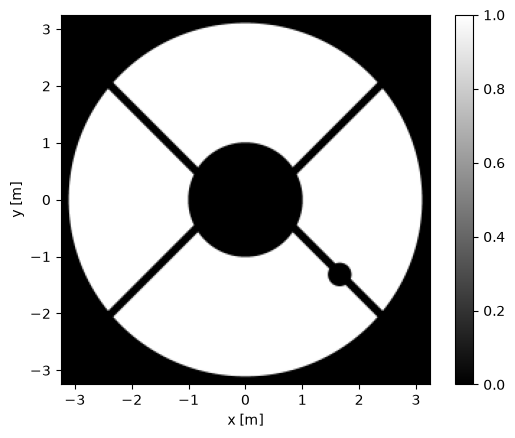

In [45]:
# Telescope / instrument constants
aperture_diameter = 6.5            # m
effective_focal_length = 71.5   # m

pupil_grid = hcipy.make_pupil_grid(256, diameter=aperture_diameter)

magellan_pupil_generator = make_magaox_bump_mask()
telescope_pupil = hp.evaluate_supersampled(magellan_pupil_generator, pupil_grid, 8)

hcipy.imshow_field(telescope_pupil, cmap='gray')
plt.colorbar()
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()


Create and select the filters: 

- Narrowband 875 filter $\lambda$ = 875nm, bandwidth = 3\%
- Broadband z' filter (here z): $\lambda$ = 908nm, bandwidth = 14\%

In [46]:
# Define and select filter
filter_875 = {'name': '875 nm', 'wavelength': 875e-9, 'bandwidth': 0.03} 
filter_z   = {'name': 'z band', 'wavelength': 908e-9, 'bandwidth': 0.13/0.908}
# 875 filter is to narrowband, not enough flux for the detection of faint objects. Use z band instead.
# filter = filter_875
filter = filter_z
wavelength = filter['wavelength']
bandwidth = filter['bandwidth']


Propagate a Monochomatic (at central wavelength of the filter) wavefront towards the focal plane.\
Propagate a bandwidth for each filter

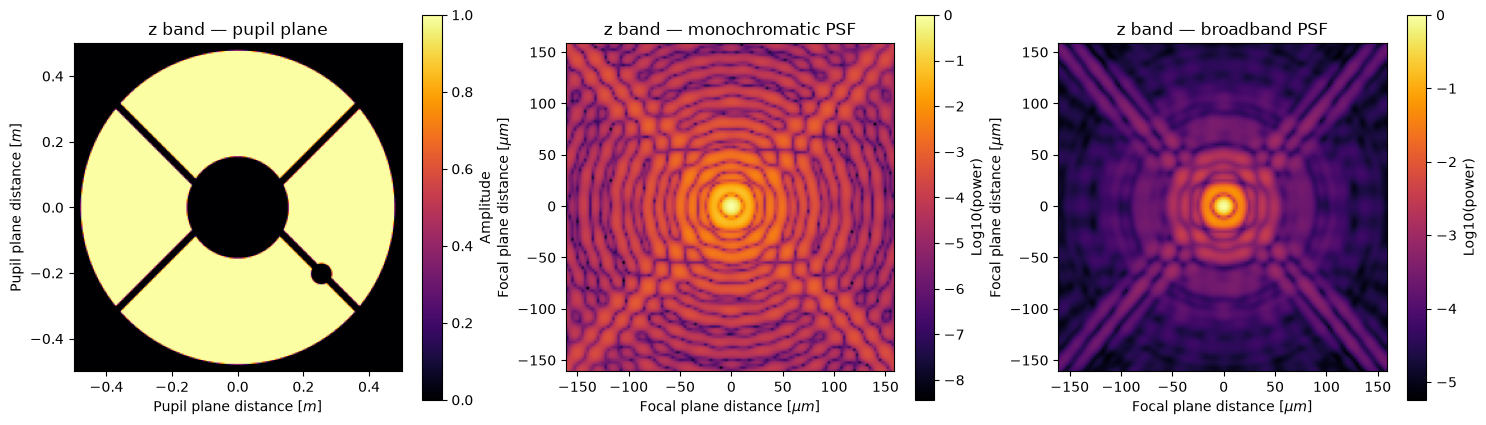

In [47]:
wavefront = hcipy.Wavefront(telescope_pupil, wavelength=wavelength) # create wavefront object

focal_grid = hcipy.make_focal_grid(q=4, num_airy=16, pupil_diameter=aperture_diameter,
                                    focal_length=effective_focal_length, reference_wavelength=wavelength)

fraun = hcipy.FraunhoferPropagator(pupil_grid, focal_grid, focal_length=effective_focal_length)

focal_image = fraun.forward(wavefront) #plot the monochromatic PSF

focal_total = 0
for wlen in wavelength * np.linspace(1 - bandwidth / 2., 1 + bandwidth / 2., 11):
    wavefront = hcipy.Wavefront(telescope_pupil, wlen)
    focal_total += fraun.forward(wavefront).power




fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].set_title('Pupil Plane')
ax[1].set_title('Focal Plane')
ax[2].set_title('Focal Plane (Broadband)')

hcipy.imshow_field(wavefront.amplitude, grid_units = aperture_diameter, ax=ax[0], cmap='inferno')
ax[0].set_xlabel(r'Pupil plane distance [$m$]')
ax[0].set_ylabel(r'Pupil plane distance [$m$]')
ax[0].set_title(filter['name'] + ' — pupil plane')
ax[0].set_aspect('equal')
plt.colorbar(ax[0].images[0], ax=ax[0], label='Amplitude')

hcipy.imshow_field(np.log10(focal_image.power / focal_image.power.max()), grid_units=1e-6, ax=ax[1],cmap='inferno')
ax[1].set_xlabel(r'Focal plane distance [$\mu m$]')
ax[1].set_ylabel(r'Focal plane distance [$\mu m$]')
ax[1].set_title(filter['name'] + ' — monochromatic PSF')
ax[1].set_aspect('equal')
plt.colorbar(ax[1].images[0], ax=ax[1], label='Log10(power)')


hcipy.imshow_field(np.log10(focal_total / focal_total.max()), grid_units=1e-6, ax=ax[2],cmap='inferno')
ax[2].set_xlabel(r'Focal plane distance [$\mu m$]')
ax[2].set_ylabel(r'Focal plane distance [$\mu m$]')
ax[2].set_title(filter['name'] + ' — broadband PSF')
ax[2].set_aspect('equal')

plt.colorbar(ax[2].images[0], ax=ax[2], label='Log10(power)')
plt.show()


Import CSV for PIAA and FPM

In [48]:
piaa0_csv = np.loadtxt('utils/piaa0_CaF2.csv', delimiter=',', skiprows=1)   # [radius_m, cut_depth_m]
piaa1_csv = np.loadtxt('utils/piaa1_CaF2.csv', delimiter=',', skiprows=1)
radial_d0, profile0 = piaa0_csv[:, 0], -piaa0_csv[:, 1]
radial_d1, profile1 = piaa1_csv[:, 0], -piaa1_csv[:, 1]
min_0=np.min(radial_d0)
min_1=np.min(radial_d1)
profile0=profile0-min_0
profile1=profile1-min_1

def load_fpm_csv(path):
    """Load the Keyence VK-X1000 height map (FPM.csv). Returns (meta, height_m)."""
    with open(path) as f:
        rows = list(csv.reader(f))
    header_i = next(i for i, r in enumerate(rows) if r and r[0] == 'Height')
    meta = {r[0]: r[1] for r in rows[:header_i] if len(r) >= 2}
    height_um = np.array([[float(v) for v in r] for r in rows[header_i + 1:] if r])
    return meta, height_um * 1e-6   # metres

fpm_meta, fpm_height = load_fpm_csv('utils/FPM.csv')   # loaded now; built into an FPM later


Create the lense propagators 

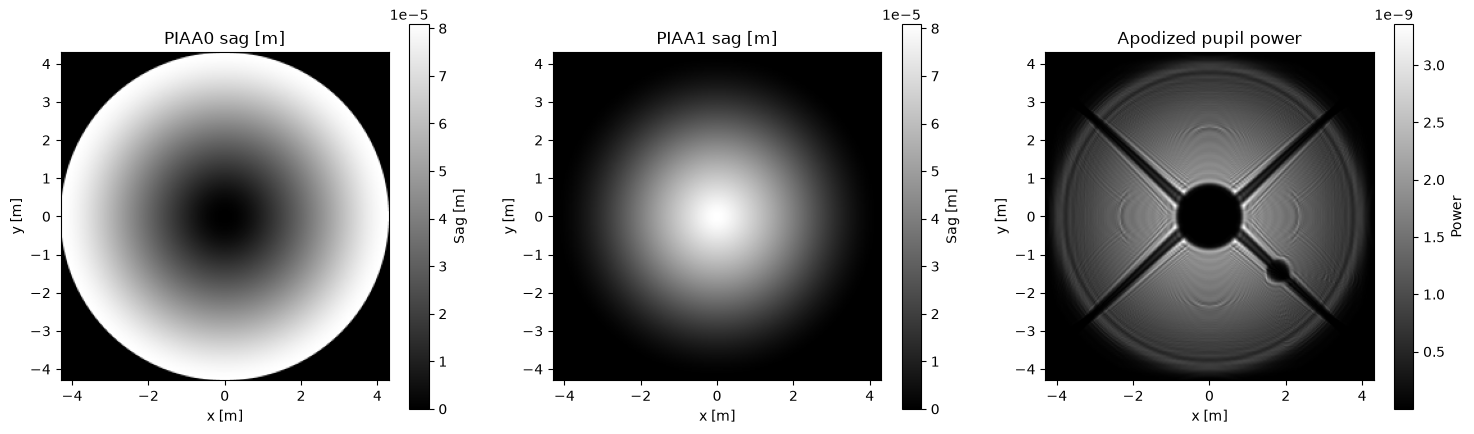

In [49]:
d_pupil_piaa0 = 37.2e-3   # m, pupil plane -> PIAA0
d_piaa0_piaa1 = 60.2e-3   # m, PIAA0 -> PIAA1
pupil_diameter = 8.6e-3   # m, pupil diameter (for the wavefront)
ref_ind_lenses = hcipy.get_refractive_index('CAF2')   # n(lambda)

piaa_pupil_grid = hcipy.make_pupil_grid(256, diameter=pupil_diameter)
aperture = hp.evaluate_supersampled(make_magaox_bump_mask(aperture_scale="pupil"), piaa_pupil_grid, 8)

prop_pupil_piaa0 = hp.FresnelPropagator(aperture.grid,d_pupil_piaa0) #AngularSpectrumPropagator
prop_piaa0_piaa1 = hp.FresnelPropagator(aperture.grid,d_piaa0_piaa1)
prop_piaa1_pupil = hp.FresnelPropagator(aperture.grid,d_piaa0_piaa1+d_pupil_piaa0)

prop_LS_piaa1 = hp.FresnelPropagator(aperture.grid,d_pupil_piaa0)
prop_piaa1_piaa0 = hp.FresnelPropagator(aperture.grid,d_piaa0_piaa1)
prop_piaa0_LS = hp.FresnelPropagator(aperture.grid,d_piaa0_piaa1+d_pupil_piaa0)


sag0 = hp.Field(np.interp(aperture.grid.as_('polar').r,radial_d0,-profile0),aperture.grid)
sag1 = hp.Field(np.interp(aperture.grid.as_('polar').r,radial_d1,-profile1),aperture.grid)

piaa0 = hp.SurfaceApodizer(-sag0, ref_ind_lenses)
piaa1 = hp.SurfaceApodizer(-sag1, ref_ind_lenses)

#TODO: check what separation is

separation = 0
wf = hp.Wavefront(aperture*np.exp(2j * np.pi * separation * aperture.grid.x / pupil_diameter), wavelength=wavelength)

wf_piaa0 = piaa0.forward(prop_pupil_piaa0.forward(wf))
wf_piaa1 = piaa1.forward(prop_piaa0_piaa1.forward(wf_piaa0))
wf_apodized = prop_piaa1_pupil.backward(wf_piaa1)


#plot lenses
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].set_title('PIAA0 sag [m]')
ax[1].set_title('PIAA1 sag [m]')
ax[2].set_title('Apodized pupil power')
hcipy.imshow_field(sag0*hp.evaluate_supersampled(hp.make_circular_aperture(pupil_diameter), piaa_pupil_grid, 8), cmap='gray', grid_units=1e-3, ax=ax[0])
hcipy.imshow_field(sag1*hp.evaluate_supersampled(hp.make_circular_aperture(pupil_diameter), piaa_pupil_grid, 8), cmap='gray', grid_units=1e-3, ax=ax[1])
hcipy.imshow_field(wf_apodized.power, cmap='grey', grid_units=1e-3, ax=ax[2])
ax[0].set_xlabel('x [m]')
ax[0].set_ylabel('y [m]')
ax[1].set_xlabel('x [m]')
ax[1].set_ylabel('y [m]')
ax[2].set_xlabel('x [m]')
ax[2].set_ylabel('y [m]')
plt.colorbar(ax[0].images[0], ax=ax[0], label='Sag [m]')
plt.colorbar(ax[1].images[0], ax=ax[1], label='Sag [m]')
plt.colorbar(ax[2].images[0], ax=ax[2], label='Power')
plt.show()


Plot lense profile and FPM shape

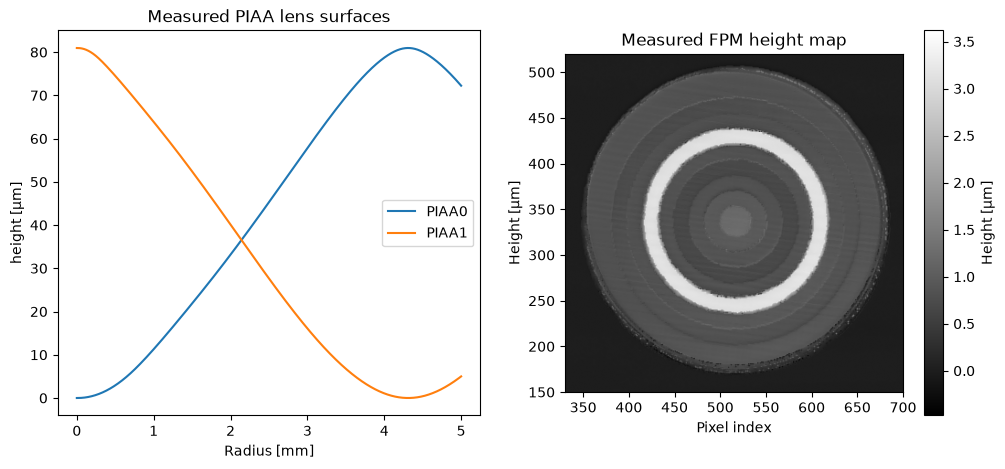

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))   # fig, ax — correct order, 2 columns

ax[0].plot(radial_d0 * 1e3, (profile0.max()-profile0) * 1e6, label='PIAA0', color='C0')
ax[0].plot(radial_d1 * 1e3, (profile1.max()-profile1) * 1e6, label='PIAA1', color='C1')
ax[0].set_xlabel('Radius [mm]')
ax[0].set_ylabel('height [µm]')
ax[0].set_title('Measured PIAA lens surfaces')
ax[0].legend()

ax[1].imshow(fpm_height * 1e6, cmap='grey')
ax[1].set_xlim(330, 700)
ax[1].set_ylim(150, 520)
ax[1].set_xlabel('Pixel index')
ax[1].set_ylabel('Height [µm]')
ax[1].set_title('Measured FPM height map')
plt.colorbar(ax[1].images[0], ax=ax[1], label='Height [µm]')
plt.show()


Implement FPM using the csv data

In [ ]:
n_rings=10
expected_max_radius_norm=0.75
expected_heights=np.array([1.26196831, 0.94074998, 0.77836148, 0.6366583 , 0.7739299 , 3.19782967, 0.85539274, 0.79005693, 0.88346143, 0.87813155]) #microns
pixel_size = 0.279e-6                              # m/px, from Keyence header
F_number=69
SR=wavelength * F_number


def prop_fpm(wavefront, fpm_height, wavelength, F_number): 
   """Propagate a wavefront through the FPM."""
   
   
   return wavefront
wf_fpm = prop_fpm(wf_apodized, fpm_height, wavelength, F_number)



ValueError: fp and xp are not of the same length.

TypeError: Invalid shape (65536,) for image data

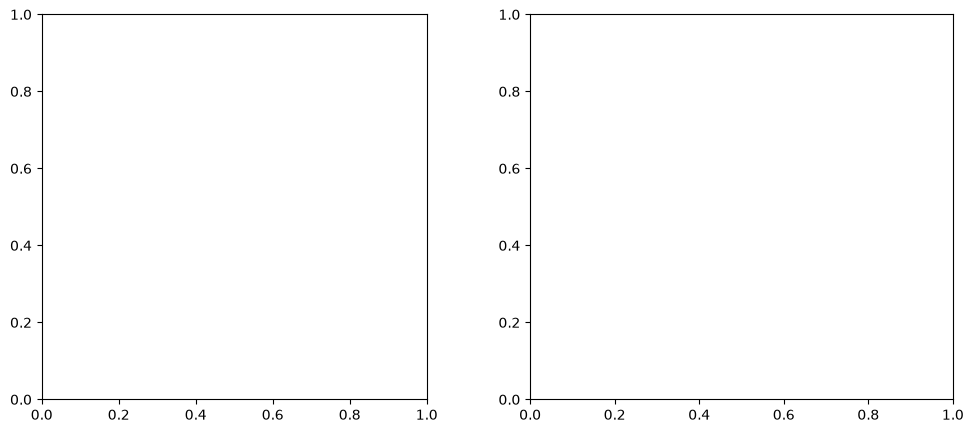

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(np.log10(wf_apodized.power / wf_apodized.power.max()), cmap='inferno')
ax[0].set_title('Apodized pupil power')
ax[0].set_xlabel('x [m]')
ax[0].set_ylabel('y [m]')
ax[1].imshow(np.log10(wf_fpm.power / wf_fpm.power.max()), cmap='inferno')
ax[1].set_title('FPM pupil power')
ax[1].set_xlabel('x [m]')
ax[1].set_ylabel('y [m]')
plt.show()
